# FIRMS MODIS hotspot EDA

Explore the downloaded MODIS Collection 6.1 archive before creating 5 × 5 km cell-day labels. A row is a detected hotspot pixel, **not** a distinct fire incident or burned area.

Mahdiyasa et al. (2026) use daily 2020–2024 MODIS detections with `confidence > 80`. The paper names Collection 6; this local archive is Collection 6.1, which we must document as a source difference. See [NASA FIRMS field definitions](https://firms.modaps.eosdis.nasa.gov/descriptions/FIRMS_MODIS_Firehotspots.html) and the [MODIS fire guide](https://www.earthdata.nasa.gov/s3fs-public/2023-09/MODIS_C6_C6.1_Fire_User_Guide_1.0.pdf).


In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import shapely
from shapely.geometry import shape
from shapely.plotting import plot_polygon


## 1. Load and check the archive

Keep `version` as text. `acq_date` and `acq_time` are UTC; this EDA groups by the reported acquisition date.


In [2]:
source = Path("data/raw/Firms/DL_FIRE_M-C61_814923/fire_archive_M-C61_814923.csv")
firms = pd.read_csv(source, dtype={"version": "string"})
firms["date"] = pd.to_datetime(firms["acq_date"], errors="coerce")
print(f"Rows: {len(firms):,}; dates: {firms.date.min().date()} to {firms.date.max().date()}")
print(f"Distinct dates with detections: {firms.date.nunique():,}")
firms.head()


Rows: 47,686; dates: 2020-01-01 to 2024-12-30
Distinct dates with detections: 1,503


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,date
0,5.4289,114.7123,306.0,1.0,1.0,2020-01-01,1449,Terra,MODIS,40,6.03,293.9,4.1,N,3,2020-01-01
1,5.8772,114.2963,310.2,1.2,1.1,2020-01-02,307,Terra,MODIS,32,6.03,292.0,7.5,D,3,2020-01-02
2,-2.9786,113.9921,310.7,1.6,1.2,2020-01-02,310,Terra,MODIS,35,6.03,292.5,12.1,D,0,2020-01-02
3,-0.4049,116.5285,316.9,1.3,1.1,2020-01-04,257,Terra,MODIS,74,6.03,292.0,16.2,D,0,2020-01-04
4,-1.8908,115.8613,317.4,1.3,1.1,2020-01-04,257,Terra,MODIS,73,6.03,293.8,12.9,D,0,2020-01-04


In [3]:
quality = pd.DataFrame({"dtype": firms.dtypes.astype(str),
                        "missing": firms.isna().sum(),
                        "unique_values": firms.nunique(dropna=True)})
print(f"Exact duplicate rows: {firms.duplicated().sum():,}; invalid dates: {firms.date.isna().sum():,}")
print(f"Coordinate range: {firms.longitude.min():.3f}–{firms.longitude.max():.3f}°E; {firms.latitude.min():.3f}–{firms.latitude.max():.3f}°N")
quality


Exact duplicate rows: 0; invalid dates: 0
Coordinate range: 108.001–119.999°E; -4.999–7.998°N


,dtype,missing,unique_values
latitude,float64,0,33056
longitude,float64,0,35455
brightness,float64,0,894
scan,float64,0,39
track,float64,0,11
acq_date,str,0,1503
acq_time,int64,0,508
satellite,str,0,2
instrument,str,0,1
confidence,int64,0,101


## 2. Confidence and other fields

NASA's `type` codes are 0 presumed vegetation fire, 1 active volcano, 2 other static land source, and 3 offshore. We show them but do **not** add a type filter here: the paper specifies the confidence threshold, while an extra type rule would be our decision.


In [4]:
for field in ["satellite", "instrument", "version", "type", "daynight"]:
    print(f"\n{field}\n{firms[field].value_counts(dropna=False).sort_index().to_string()}")
high_conf = firms.loc[firms.confidence > 80].copy()  # 80 itself is excluded
print(f"\nConfidence > 80: {len(high_conf):,} / {len(firms):,} ({len(high_conf)/len(firms):.1%})")
print("Retained type codes:", high_conf.type.value_counts().sort_index().to_dict())



satellite
satellite
Aqua     36829
Terra    10857

instrument
instrument
MODIS    47686

version
version
6.03     14254
61.03    33432

type
type
0    43997
2     2768
3      921

daynight
daynight
D    40736
N     6950

Confidence > 80: 9,472 / 47,686 (19.9%)
Retained type codes: {0: 9165, 2: 202, 3: 105}


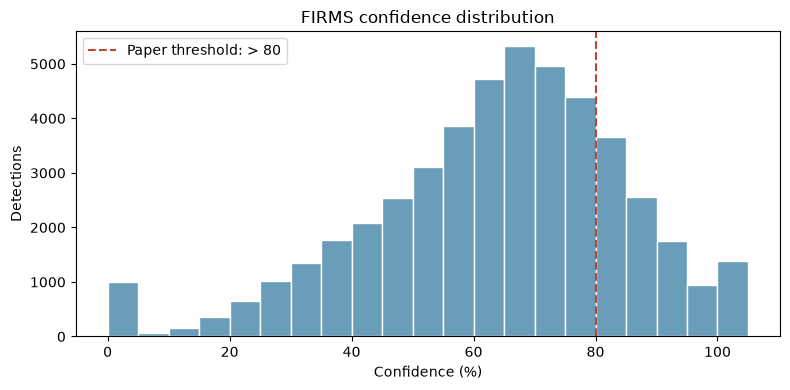

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(firms.confidence, bins=range(0, 106, 5), color="#6a9db9", edgecolor="white")
ax.axvline(80, color="#b74635", linestyle="--", label="Paper threshold: > 80")
ax.set(xlabel="Confidence (%)", ylabel="Detections", title="FIRMS confidence distribution")
ax.legend(); plt.tight_layout(); plt.show()


## 3. Yearly and monthly detections

A date with no archive row is not a CSV error. Explicit zero-fire **cell-days** can be created only after we fix the study grid.


In [6]:
by_year = pd.DataFrame({
    "all_detections": firms.groupby(firms.date.dt.year).size(),
    "confidence_gt_80": high_conf.groupby(high_conf.date.dt.year).size(),
}).fillna(0).astype(int)
by_year["retained_share"] = by_year.confidence_gt_80 / by_year.all_detections
by_year


,all_detections,confidence_gt_80,retained_share
date,,,
2020,5332,729,0.136722
2021,5206,804,0.154437
2022,3716,450,0.121098
2023,22853,5430,0.237606
2024,10579,2059,0.194631


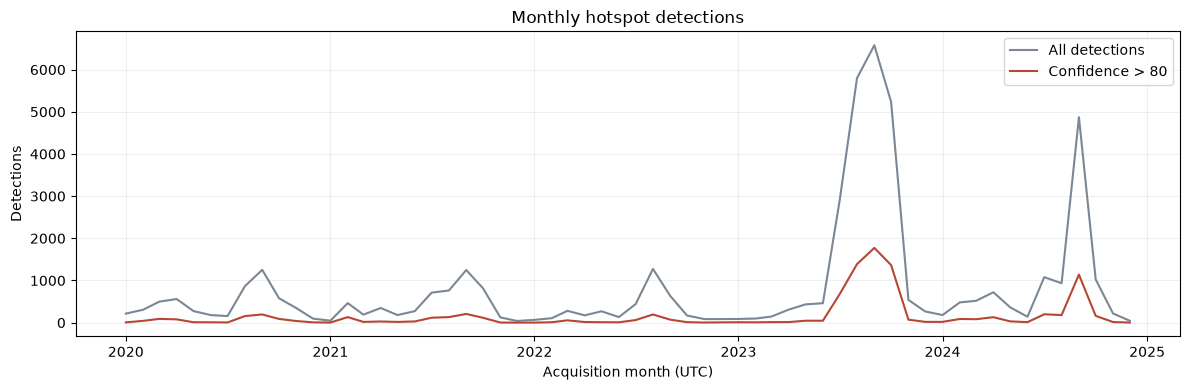

In [8]:
months = pd.date_range("2020-01-01", "2024-12-01", freq="MS")
monthly_all = firms.groupby(pd.Grouper(key="date", freq="MS")).size().reindex(months, fill_value=0)
monthly_high = high_conf.groupby(pd.Grouper(key="date", freq="MS")).size().reindex(months, fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(months, monthly_all, label="All detections", color="#7b8794")
ax.plot(months, monthly_high, label="Confidence > 80", color="#b74635")
ax.set(xlabel="Acquisition month (UTC)", ylabel="Detections", title="Monthly hotspot detections")
ax.grid(alpha=0.2); ax.legend(); plt.tight_layout(); plt.show()


## 4. Map hotspots against Kalimantan

The FIRMS download covers a rectangle larger than Kalimantan. We count retained detections inside the five BIG province boundaries and inside **any** polygon from the candidate BIG peatland layer. That is only a spatial check: we have not decided the final peatland classes or grid. Boundary simplification below is only for plotting; membership uses the original geometry.


In [9]:
with Path("data/raw/boundaries/big_kalimantan_provinces.geojson").open(encoding="utf-8") as file:
    province_geojson = json.load(file)
with Path("data/raw/peatland/big_peta_lahan_gambut_kalimantan.geojson").open(encoding="utf-8") as file:
    peat_geojson = json.load(file)
def keep_xy(coordinates):
    if isinstance(coordinates[0], (int, float)):
        return coordinates[:2]  # discard BIG's Z/M values
    return [keep_xy(part) for part in coordinates]
provinces = [(feature["properties"]["WADMPR"], shape({
    "type": feature["geometry"]["type"],
    "coordinates": keep_xy(feature["geometry"]["coordinates"]),
})) for feature in province_geojson["features"]]
mapped_polygons = [shape(feature["geometry"]) for feature in peat_geojson["features"]]
province_union = shapely.union_all([geom for _, geom in provinces])
mapped_union = shapely.union_all(mapped_polygons)
lon, lat = high_conf.longitude.to_numpy(), high_conf.latitude.to_numpy()
high_conf["in_kalimantan"] = shapely.contains_xy(province_union, lon, lat)
high_conf["in_mapped_layer"] = shapely.contains_xy(mapped_union, lon, lat)
spatial_counts = pd.Series({
    "Confidence > 80 in full archive rectangle": len(high_conf),
    "Inside five Kalimantan provinces": int(high_conf.in_kalimantan.sum()),
    "Inside any candidate BIG mapped polygon": int(high_conf.in_mapped_layer.sum()),
    "Inside both": int((high_conf.in_kalimantan & high_conf.in_mapped_layer).sum()),
}, name="detections")
spatial_counts.to_frame()


,detections
Confidence > 80 in full archive rectangle,9472
Inside five Kalimantan provinces,8673
Inside any candidate BIG mapped polygon,1908
Inside both,1908


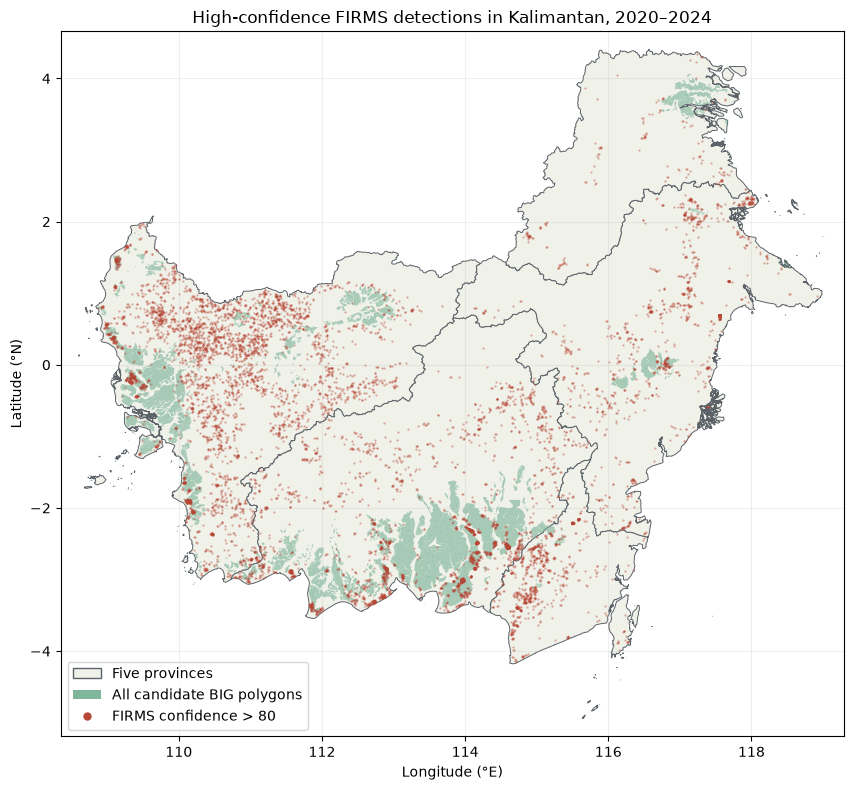

In [10]:
fig, ax = plt.subplots(figsize=(11, 8))
for _, geom in provinces:
    plot_polygon(geom.simplify(0.003, preserve_topology=True), ax=ax, add_points=False,
                 facecolor="#f0f1e9", edgecolor="#5b6268", linewidth=0.7)
for geom in mapped_polygons:
    plot_polygon(geom.simplify(0.01, preserve_topology=True), ax=ax, add_points=False,
                 facecolor="#80b69c", edgecolor="none", alpha=0.65)
inside = high_conf.loc[high_conf.in_kalimantan]
ax.scatter(inside.longitude, inside.latitude, s=2.5, c="#b74635", alpha=0.45, linewidths=0)
bounds = [geom.bounds for _, geom in provinces]
ax.set_xlim(min(b[0] for b in bounds)-0.25, max(b[2] for b in bounds)+0.25)
ax.set_ylim(min(b[1] for b in bounds)-0.25, max(b[3] for b in bounds)+0.25)
ax.set_aspect("equal", adjustable="box")
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)",
       title="High-confidence FIRMS detections in Kalimantan, 2020–2024")
ax.grid(alpha=0.2)
ax.legend(handles=[Patch(facecolor="#f0f1e9", edgecolor="#5b6268", label="Five provinces"),
                   Patch(facecolor="#80b69c", label="All candidate BIG polygons"),
                   plt.Line2D([], [], marker="o", linestyle="", markersize=5,
                              color="#b74635", label="FIRMS confidence > 80")], loc="lower left")
plt.tight_layout(); plt.show()


## What remains before modeling

Choose and document the peatland-class rule and 5 × 5 km grid. Then the preprocessing pipeline can assign retained detections to grid cell-days and create explicit zeros. The archive's `type` codes and Collection 6.1 versus the paper's Collection 6 should remain visible as methodological decisions.
